# [_03_] Model Training & Comparison


Goal is train several classifiers and compare them fairly.


- every model uses the **same training data**;
- every model uses the **same 5 cross-validation folds**;
- every model uses the **same preprocessing pipeline**;
- the main metric is **macro F1** (each class counts the same);
- the test set is **not loaded**. It stays locked until the final evaluation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, recall_score
from sklearn.model_selection import cross_val_predict, cross_validate

# Allow importing src/ when the notebook is opened from notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').exists())
sys.path.insert(0, str(ROOT))

from src import config
from src.models import SCORING, get_cv, get_models
from src.preprocessing import build_model_pipeline, prepare_features, prepare_target

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

## [_1_] Load the training set

Only `train.csv` is loaded.

In [2]:
train = pd.read_csv(config.DATA_INTERIM / 'train.csv')

# Student_ID and the target are not part of the features
X_train = prepare_features(train)
y_train = prepare_target(train)

print('X_train shape:', X_train.shape)
print('Classes:', sorted(y_train.unique()))

X_train shape: (1600, 15)
Classes: ['High', 'Low', 'Medium']


## [_2_] Comparison protocol

- **5-fold stratified cross-validation**: the training set is cut into 5 parts. Each model is trained on 4 parts and scored on the 5th, five times.
- The folds are created with a fixed seed, so **all models are scored on exactly the same folds**.
- **Dummy baseline**: a model that guesses at random. Every real model must clearly beat it (about 0.33 with 3 balanced classes).

In [3]:
cv = get_cv()
models = get_models()

print('Cross-validation:', cv)
print('Metrics:', SCORING)
print('Models:', list(models.keys()))

Cross-validation: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Metrics: ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'roc_auc_ovr']
Models: ['Dummy (baseline)', 'Logistic Regression', 'Random Forest', 'Gradient Boosting']


## [_3_] Train & score every model

Each model is placed in the same pipeline (preprocessing + model). `cross_validate` refits the whole pipeline inside each fold, so imputation and scaling never see the validation fold.

In [4]:
results = []

for name, model in models.items():
    pipeline = build_model_pipeline(model)

    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=SCORING)

    # Keep the mean of the 5 folds for each metric
    row = {'model': name}
    for metric in SCORING:
        row[metric] = scores[f'test_{metric}'].mean()

    # Standard deviation of the main metric = stability across folds
    row['f1_macro_std'] = scores['test_f1_macro'].std()
    row['fit_time_s'] = scores['fit_time'].mean()

    results.append(row)
    print(f'{name}: done')

Dummy (baseline): done
Logistic Regression: done
Random Forest: done
Gradient Boosting: done


In [5]:
results_table = pd.DataFrame(results).set_index('model')
results_table = results_table.sort_values('f1_macro', ascending=False)
results_table.round(3)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,f1_macro_std,fit_time_s
model,,,,,,,,
Logistic Regression,0.752,0.752,0.751,0.751,0.752,0.905,0.022,0.124
Gradient Boosting,0.683,0.684,0.682,0.683,0.684,0.857,0.015,1.787
Random Forest,0.669,0.662,0.668,0.663,0.664,0.849,0.021,1.108
Dummy (baseline),0.339,0.339,0.339,0.339,0.339,0.504,0.025,0.062


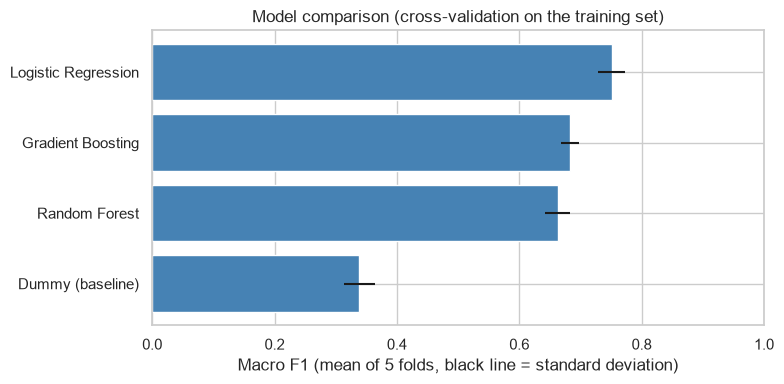

In [6]:
plot_data = results_table.sort_values('f1_macro')

plt.figure(figsize=(8, 4))
plt.barh(plot_data.index, plot_data['f1_macro'], xerr=plot_data['f1_macro_std'], color='steelblue')
plt.xlim(0, 1)
plt.xlabel('Macro F1 (mean of 5 folds, black line = standard deviation)')
plt.title('Model comparison (cross-validation on the training set)')
plt.tight_layout()
plt.savefig(config.FIGURES / '03_model_comparison.png', dpi=120)
plt.show()

## [_4_] Confusion matrices (out-of-fold predictions)

`cross_val_predict` predicts each training row with a model that **did not see that row** during fitting. This gives honest confusion matrices without touching the test set.

In [7]:
oof_predictions = {}

for name, model in models.items():
    pipeline = build_model_pipeline(model)
    oof_predictions[name] = cross_val_predict(pipeline, X_train, y_train, cv=cv)
    print(f'{name}: done')

Dummy (baseline): done
Logistic Regression: done
Random Forest: done
Gradient Boosting: done


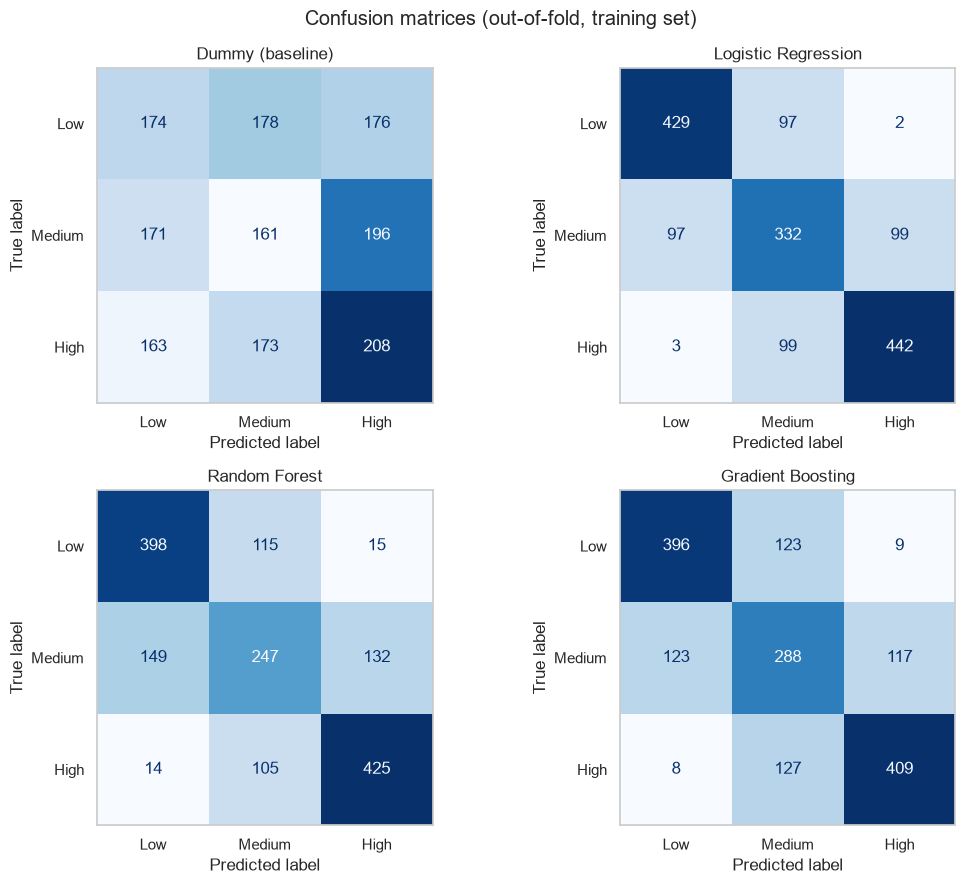

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, predictions) in zip(axes.ravel(), oof_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_train,
        predictions,
        labels=config.TARGET_ORDER,
        cmap='Blues',
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)
    ax.grid(False)

plt.suptitle('Confusion matrices (out-of-fold, training set)')
plt.tight_layout()
plt.savefig(config.FIGURES / '03_confusion_matrices.png', dpi=120)
plt.show()

## [_5_] Scores per class

Precision, recall and F1 for Low, Medium and High, for each model.

In [9]:
for name, predictions in oof_predictions.items():
    print(f'\n===== {name} =====')
    print(classification_report(y_train, predictions, labels=config.TARGET_ORDER, digits=3))


===== Dummy (baseline) =====
              precision    recall  f1-score   support

         Low      0.343     0.330     0.336       528
      Medium      0.314     0.305     0.310       528
        High      0.359     0.382     0.370       544

    accuracy                          0.339      1600
   macro avg      0.339     0.339     0.339      1600
weighted avg      0.339     0.339     0.339      1600


===== Logistic Regression =====
              precision    recall  f1-score   support

         Low      0.811     0.812     0.812       528
      Medium      0.629     0.629     0.629       528
        High      0.814     0.812     0.813       544

    accuracy                          0.752      1600
   macro avg      0.751     0.751     0.751      1600
weighted avg      0.752     0.752     0.752      1600


===== Random Forest =====
              precision    recall  f1-score   support

         Low      0.709     0.754     0.731       528
      Medium      0.529     0.468     0

In [10]:
# Recall per class: among the rows of a class, how many did the model find?
recall_rows = []

for name, predictions in oof_predictions.items():
    recalls = recall_score(y_train, predictions, labels=config.TARGET_ORDER, average=None)
    recall_rows.append({
        'model': name,
        'recall_Low': recalls[0],
        'recall_Medium': recalls[1],
        'recall_High': recalls[2],
    })

recall_table = pd.DataFrame(recall_rows).set_index('model')
recall_table.round(3)

,recall_Low,recall_Medium,recall_High
model,,,
Dummy (baseline),0.330,0.305,0.382
Logistic Regression,0.812,0.629,0.812
Random Forest,0.754,0.468,0.781
Gradient Boosting,0.750,0.545,0.752


## [_6_] Most serious errors

The classes are ordered: Low < Medium < High. Confusing two neighbours (Medium and High) is less serious than confusing the two extremes.

**High predicted as Low** is the error to watch first: a row labelled High in the dataset is completely missed.

In [11]:
error_rows = []

for name, predictions in oof_predictions.items():
    high_as_low = ((y_train == 'High') & (predictions == 'Low')).sum()
    low_as_high = ((y_train == 'Low') & (predictions == 'High')).sum()
    error_rows.append({
        'model': name,
        'High_predicted_Low': int(high_as_low),
        'Low_predicted_High': int(low_as_high),
        'total_errors': int((y_train != predictions).sum()),
    })

error_table = pd.DataFrame(error_rows).set_index('model')
error_table

,High_predicted_Low,Low_predicted_High,total_errors
model,,,
Dummy (baseline),163,176,1057
Logistic Regression,3,2,397
Random Forest,14,15,530
Gradient Boosting,8,9,507


## [_7_] Keep two candidates

The two best models on macro F1 (baseline excluded) go to the optimization step. The results table is saved for the next notebook and for the Streamlit app.

In [12]:
real_models = results_table.drop(index='Dummy (baseline)')
candidates = real_models.head(2).index.tolist()

print('Candidates for optimization:', candidates)

results_path = config.ROOT / 'reports' / '03_cv_results.csv'
results_table.round(4).to_csv(results_path)
print('Results saved to:', results_path)

Candidates for optimization: ['Logistic Regression', 'Gradient Boosting']
Results saved to: C:\Users\hamza\Desktop\dev_ai\CampusWell\reports\03_cv_results.csv


## [_8_] Conclusion

- These scores come from cross-validation on the training set. The test set is still locked.
- _'Logistic Regression'_ & _'Gradient Boosting'_